Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


Text Preprocessing

In [2]:
df = df.dropna(subset=['title', 'real'])

df['title'] = df['title'].astype(str)

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

df['clean_text'] = df['title'].apply(preprocess_text)

X = df['clean_text']
y = df['real'].astype(int)

display(df[['title', 'clean_text', 'real']].head())

,title,clean_text,real
0,Kandi Burruss Explodes Over Rape Accusation on...,kandi burruss explodes over rape accusation on...,1
1,People's Choice Awards 2018: The best red carp...,peoples choice awards the best red carpet looks,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,sophia bush sends sweet birthday message to on...,1
3,Colombian singer Maluma sparks rumours of inap...,colombian singer maluma sparks rumours of inap...,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,gossip girl years later how upper east siders...,1


split dataset

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 18556
Testing Samples: 4640


Implement FastText-Style Character N-Gram Embeddings

In [4]:
fasttext_vectorizer = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3, 5),
    max_features=5000
)

X_train_fasttext = fasttext_vectorizer.fit_transform(X_train)

X_test_fasttext = fasttext_vectorizer.transform(X_test)

print("Training Matrix:", X_train_fasttext.shape)
print("Testing Matrix:", X_test_fasttext.shape)

Training Matrix: (18556, 5000)
Testing Matrix: (4640, 5000)


Train Classification Model Using FastText-Style Features

In [5]:
fasttext_model = LogisticRegression(max_iter=1000)

fasttext_model.fit(X_train_fasttext, y_train)

fasttext_predictions = fasttext_model.predict(X_test_fasttext)

print("FastText-Style Model Trained Successfully")

FastText-Style Model Trained Successfully


Apply TF-IDF for Comparison

In [6]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

tfidf_model = LogisticRegression(max_iter=1000)

tfidf_model.fit(X_train_tfidf, y_train)

tfidf_predictions = tfidf_model.predict(X_test_tfidf)

Evaluate Model Performance

In [7]:
results = []

for name, predictions in [
    ('TF-IDF', tfidf_predictions),
    ('FastText-Style Character N-Grams', fasttext_predictions)
]:

    results.append({
        'Method': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1_Score': f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Method,Accuracy,Precision,Recall,F1_Score
0,TF-IDF,0.8453,0.8523,0.9607,0.9033
1,FastText-Style Character N-Grams,0.8336,0.8435,0.9561,0.8963


Visualize Accuracy Comparison

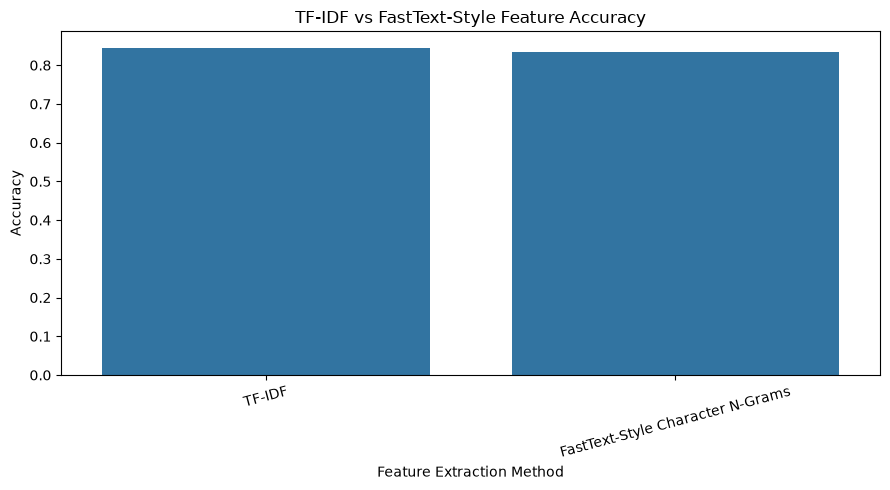

In [8]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Method',
    y='Accuracy'
)

plt.title("TF-IDF vs FastText-Style Feature Accuracy")
plt.xlabel("Feature Extraction Method")
plt.ylabel("Accuracy")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Compare All Performance Metrics

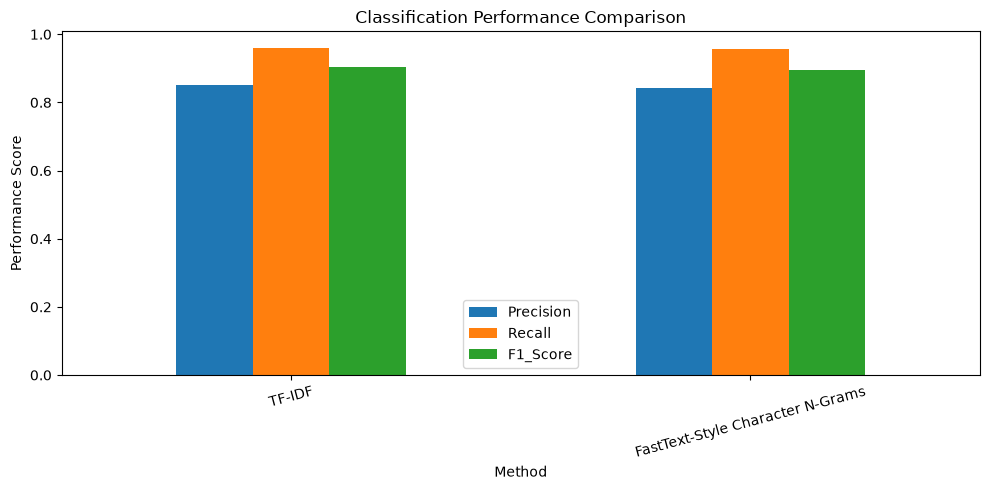

In [9]:
results_df.set_index('Method')[
    ['Precision', 'Recall', 'F1_Score']
].plot(kind='bar', figsize=(10, 5))

plt.title("Classification Performance Comparison")
plt.ylabel("Performance Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Final Results

In [10]:
print("FASTTEXT FEATURE ANALYSIS")

print("\nTotal Articles:", len(df))

print("\nVocabulary Features:", 
      X_train_fasttext.shape[1])

print("\nModel Performance:")
display(results_df.round(4))

best_model = results_df.loc[
    results_df['F1_Score'].idxmax()
]

print("\nBest Performing Method:", best_model['Method'])
print("Best F1 Score:", round(best_model['F1_Score'], 4))

FASTTEXT FEATURE ANALYSIS

Total Articles: 23196

Vocabulary Features: 5000

Model Performance:


,Method,Accuracy,Precision,Recall,F1_Score
0,TF-IDF,0.8453,0.8523,0.9607,0.9033
1,FastText-Style Character N-Grams,0.8336,0.8435,0.9561,0.8963



Best Performing Method: TF-IDF
Best F1 Score: 0.9033
